In [ ]:
!unzip -q /content/archive.zip -d /content/data && ls /content/data/head_ct/head_ct | wc -l

200


In [ ]:
import numpy as np, pandas as pd, random, torch, torch.nn as nn
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

IMG_DIR = "/content/data/head_ct/head_ct"
LABELS_CSV = "/content/data/labels.csv"
IMG_SIZE, BATCH, EPOCHS, LR, SEED = 224, 16, 20, 1e-4, 42
DEVICE = "cuda"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

labels = pd.read_csv(LABELS_CSV)
labels.columns = [c.strip() for c in labels.columns]
labels["path"] = labels["id"].apply(lambda i: f"{IMG_DIR}/{int(i):03d}.png")

train_df, tmp = train_test_split(labels, test_size=0.30, stratify=labels["hemorrhage"], random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp["hemorrhage"], random_state=SEED)
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")

MEAN, STD = [0.485,0.456,0.406], [0.229,0.224,0.225]

class DS(Dataset):
    def __init__(self, df, aug=False):
        self.df = df.reset_index(drop=True)
        ops = [transforms.RandomHorizontalFlip(), transforms.RandomRotation(15),
               transforms.RandomAffine(0, translate=(0.05,0.05), scale=(0.9,1.1)),
               transforms.ColorJitter(brightness=0.2, contrast=0.2)] if aug else []
        self.tf = transforms.Compose([transforms.Resize((IMG_SIZE,IMG_SIZE)), *ops,
                                      transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.tf(Image.open(r["path"]).convert("RGB")), torch.tensor(r["hemorrhage"], dtype=torch.float32)

train_dl = DataLoader(DS(train_df, aug=True), batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_dl   = DataLoader(DS(val_df),   batch_size=BATCH, num_workers=2, pin_memory=True)
test_dl  = DataLoader(DS(test_df),  batch_size=BATCH, num_workers=2, pin_memory=True)

model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
model.classifier = nn.Linear(model.classifier.in_features, 1)
model = model.to(DEVICE)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
loss_fn = nn.BCEWithLogitsLoss()
scaler = GradScaler("cuda")

def evaluate(dl):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in dl:
            x = x.to(DEVICE, non_blocking=True)
            with autocast("cuda"): logit = model(x).squeeze(1)
            ps.append(torch.sigmoid(logit).float().cpu().numpy()); ys.append(y.numpy())
    y_true, y_prob = np.concatenate(ys), np.concatenate(ps)
    auc = roc_auc_score(y_true, y_prob)
    tn, fp, fn, tp = confusion_matrix(y_true, (y_prob>=0.5).astype(int)).ravel()
    return auc, tp/(tp+fn+1e-9), tn/(tn+fp+1e-9), (tn,fp,fn,tp)

best = 0.0
for ep in range(1, EPOCHS+1):
    model.train(); running = 0.0
    for x, y in train_dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad()
        with autocast("cuda"):
            loss = loss_fn(model(x).squeeze(1), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        running += loss.item() * x.size(0)
    sched.step()
    auc, sens, spec, _ = evaluate(val_dl)
    print(f"ep {ep:2d}  loss={running/len(train_dl.dataset):.4f}  val_auc={auc:.4f}  sens={sens:.3f}  spec={spec:.3f}")
    if auc > best:
        best = auc; torch.save(model.state_dict(), "/content/best.pt")

model.load_state_dict(torch.load("/content/best.pt"))
auc, sens, spec, cm = evaluate(test_dl)
print(f"\n=== TEST ===  AUC={auc:.4f}  sens={sens:.3f}  spec={spec:.3f}  cm(TN,FP,FN,TP)={cm}")

train=140  val=30  test=30
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 169MB/s]


ep  1  loss=0.6624  val_auc=0.8222  sens=0.267  spec=1.000
ep  2  loss=0.4652  val_auc=0.9556  sens=0.733  spec=1.000
ep  3  loss=0.3200  val_auc=0.9822  sens=0.867  spec=1.000
ep  4  loss=0.1894  val_auc=0.9822  sens=0.933  spec=0.867
ep  5  loss=0.1471  val_auc=0.9956  sens=1.000  spec=0.933
ep  6  loss=0.1113  val_auc=1.0000  sens=1.000  spec=0.867
ep  7  loss=0.0504  val_auc=1.0000  sens=1.000  spec=1.000
ep  8  loss=0.0504  val_auc=1.0000  sens=1.000  spec=1.000
ep  9  loss=0.0690  val_auc=0.9956  sens=1.000  spec=0.933
ep 10  loss=0.0446  val_auc=0.9956  sens=1.000  spec=0.867
ep 11  loss=0.0280  val_auc=1.0000  sens=1.000  spec=0.867
ep 12  loss=0.0642  val_auc=1.0000  sens=1.000  spec=0.867
ep 13  loss=0.0354  val_auc=1.0000  sens=1.000  spec=0.867
ep 14  loss=0.0262  val_auc=1.0000  sens=1.000  spec=0.933
ep 15  loss=0.0229  val_auc=1.0000  sens=1.000  spec=0.933
ep 16  loss=0.0233  val_auc=1.0000  sens=1.000  spec=0.933
ep 17  loss=0.0217  val_auc=1.0000  sens=1.000  spec=0.8

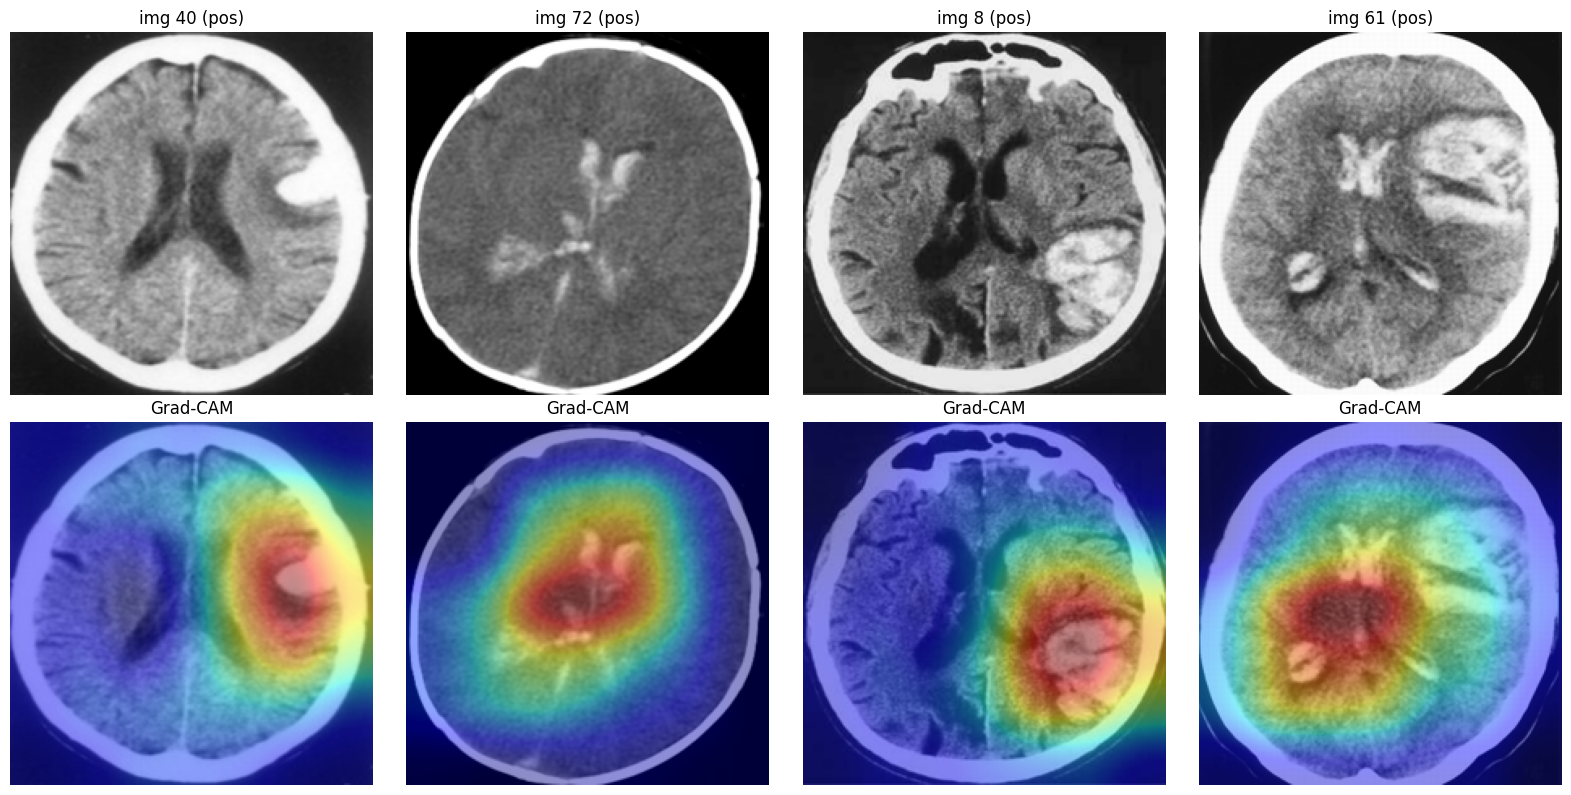

In [ ]:
import matplotlib.pyplot as plt
target_layer = model.features.denseblock4
acts, grads = {}, {}
h1 = target_layer.register_forward_hook(lambda m,i,o: acts.update(v=o.detach()))
h2 = target_layer.register_full_backward_hook(lambda m,gi,go: grads.update(v=go[0].detach()))

model.eval()
show = test_df[test_df["hemorrhage"]==1].head(4).reset_index(drop=True)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, row in show.iterrows():
    pil = Image.open(row["path"]).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    x = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])(pil).unsqueeze(0).to(DEVICE)
    x.requires_grad_(True)
    model.zero_grad()
    model(x).squeeze().backward()
    a, g = acts["v"][0], grads["v"][0]
    w = g.mean(dim=(1,2))
    cam = torch.relu((w[:,None,None]*a).sum(0))
    cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-9)).cpu().numpy()
    axes[0,i].imshow(pil, cmap="gray"); axes[0,i].set_title(f"img {row['id']} (pos)"); axes[0,i].axis("off")
    axes[1,i].imshow(pil, cmap="gray")
    axes[1,i].imshow(np.array(Image.fromarray((cam*255).astype(np.uint8)).resize((IMG_SIZE, IMG_SIZE))), cmap="jet", alpha=0.45)
    axes[1,i].set_title("Grad-CAM"); axes[1,i].axis("off")
h1.remove(); h2.remove()
plt.tight_layout(); plt.savefig("/content/gradcam.png", dpi=120, bbox_inches="tight"); plt.show()

In [ ]:
import os, json
os.makedirs("/root/.kaggle", exist_ok=True)
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump({"username": "neurosentry", "key": os.environ["KAGGLE_KEY"]}, f)
os.chmod("/root/.kaggle/kaggle.json", 0o600)
!pip install -q kaggle
!kaggle datasets list -s qureai | head -5

ref                     title                       size  lastUpdated                 downloadCount  voteCount  usabilityRating  
----------------------  -------------------  -----------  --------------------------  -------------  ---------  ---------------  
kmader/headctreads      QureAI HeadCT Reads        11461  2018-05-15 06:33:13.717000             91          2  0.29411766       
crawford/qureai-headct  Qure.ai HeadCT       27565296852  2018-05-18 03:48:28.010000          20961         19  0.3529412        


In [ ]:
!kaggle datasets download -d kmader/headctreads -p /content/labels --unzip
!ls /content/labels
import pandas as pd
print("=== prediction_probabilities.csv ===")
print(pd.read_csv("/content/labels/prediction_probabilities.csv").head(3))
print("\ncolumns:", list(pd.read_csv("/content/labels/prediction_probabilities.csv").columns))

Dataset URL: https://www.kaggle.com/datasets/kmader/headctreads
License(s): CC-BY-NC-SA-4.0
100% 11.2k/11.2k [00:00<00:00, 36.1MB/s]

prediction_probabilities.csv  reads.csv
=== prediction_probabilities.csv ===
           name Category_New   ICH   IPH   IVH   SDH   EDH   SAH  \
0  CQ500-CT-427           B2  0.99  0.46  0.07  0.36  0.03  0.33   
1  CQ500-CT-181           B2  0.99  0.63  0.00  0.68  0.22  0.22   
2   CQ500-CT-99           B1  0.25  0.01  0.00  0.08  0.00  0.12   

   CalvarialFracture  MassEffect  MidlineShift  
0           0.029752        0.62          0.20  
1           0.975000        1.00          1.00  
2           0.029752        0.22          0.02  

columns: ['name', 'Category_New', 'ICH', 'IPH', 'IVH', 'SDH', 'EDH', 'SAH', 'CalvarialFracture', 'MassEffect', 'MidlineShift']


In [ ]:
!pip install -q -U huggingface_hub

import os, subprocess, time
from google.colab import userdata
from huggingface_hub import HfApi, create_repo

TOKEN = userdata.get("HF_TOKEN")
REPO  = "neurosentry/cq500"
api = HfApi(token=TOKEN)

# 1) Ensure repo exists
create_repo(REPO, token=TOKEN, repo_type="dataset", exist_ok=True, private=False)
print(f"repo ready: https://huggingface.co/datasets/{REPO}")

# 2) Push labels (few KB, instant)
for name in ("reads.csv", "prediction_probabilities.csv"):
    api.upload_file(path_or_fileobj=f"/content/labels/{name}",
                    path_in_repo=name, repo_id=REPO, repo_type="dataset")
print("labels uploaded")

# 3) Push each qct folder as one tar; skip anything already up (resume-friendly)
existing = set(api.list_repo_files(REPO, repo_type="dataset"))
print(f"already on HF: {sorted(existing)}")

folders = sorted(f for f in os.listdir("/content/cq500_data") if f.startswith("qct"))
for folder in folders:
    tar_name, tar_path = f"{folder}.tar", f"/content/{folder}.tar"
    if tar_name in existing:
        print(f"[{folder}] already on HF, skip"); continue
    t0 = time.time()
    print(f"[{folder}] tarring...")
    subprocess.run(["tar", "-cf", tar_path, "-C", "/content/cq500_data", folder], check=True)
    size_gb = os.path.getsize(tar_path) / 1e9
    print(f"[{folder}]   tar={size_gb:.1f}GB in {time.time()-t0:.0f}s, uploading...")
    t1 = time.time()
    api.upload_file(path_or_fileobj=tar_path, path_in_repo=tar_name,
                    repo_id=REPO, repo_type="dataset")
    print(f"[{folder}]   uploaded in {time.time()-t1:.0f}s")
    os.remove(tar_path)

print("\n=== ALL DONE — data is on HF ===")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 795.8/795.8 kB 19.1 MB/s eta 0:00:00
repo ready: https://huggingface.co/datasets/neurosentry/cq500
labels uploaded
already on HF: ['.gitattributes', 'prediction_probabilities.csv', 'reads.csv']
[qct01] tarring...
[qct01]   tar=2.7GB in 33s, uploading...


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /content/qct01.tar          :   0%|          | 1.05MB / 2.65GB            

[qct01]   uploaded in 46s
[qct02] tarring...
[qct02]   tar=2.2GB in 25s, uploading...


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

... (67 outputs left out)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /content/qct19.tar          :   0%|          |  550kB /  561MB            

[qct19]   uploaded in 28s

=== ALL DONE — data is on HF ===


In [ ]:

!pip install -q -U huggingface_hub
from huggingface_hub import hf_hub_download
import os

REPO = "neurosentry/cq500"
os.makedirs("/content/cq500", exist_ok=True)

# labels (few KB, instant)
for f in ("reads.csv", "prediction_probabilities.csv"):
    hf_hub_download(repo_id=REPO, filename=f, repo_type="dataset",
                    local_dir="/content/cq500")

# one qct tar (~2.7 GB, ~2 min)
tar_path = hf_hub_download(repo_id=REPO, filename="qct01.tar", repo_type="dataset",
                           local_dir="/content/cq500")
print(f"downloaded to: {tar_path}")

# extract
import subprocess, time
os.makedirs("/content/cq500_data", exist_ok=True)
t0 = time.time()
subprocess.run(["tar", "-xf", tar_path, "-C", "/content/cq500_data"], check=True)
print(f"extracted in {time.time()-t0:.0f}s")
os.remove(tar_path)
!ls /content/cq500_data/qct01 | head -5
!echo "..."
!ls /content/cq500_data/qct01 | wc -l

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 796.8/796.8 kB 6.5 MB/s eta 0:00:00


reads.csv:   0%|          | 0.00/50.0k [00:00<?, ?B/s]

prediction_probabilities.csv:   0%|          | 0.00/28.4k [00:00<?, ?B/s]

qct01.tar: reconstructing file:   0%|          |  0.00B / 2.65GB            

qct01.tar: downloading bytes:           |  0.00B            

downloaded to: /content/cq500/qct01.tar
extracted in 14s
CQ500CT0 CQ500CT0
CQ500CT100 CQ500CT100
CQ500CT101 CQ500CT101
CQ500CT102 CQ500CT102
CQ500CT103 CQ500CT103
...
20


In [ ]:

import os, random
random.seed(42)

scan_folders = sorted(os.listdir("/content/cq500_data/qct01"))
print(f"scans in qct01: {len(scan_folders)}")

# Look at 3 random scans in detail
for sf in random.sample(scan_folders, 3):
    sf_path = f"/content/cq500_data/qct01/{sf}"
    print(f"\n=== {sf} ===")
    for study in os.listdir(sf_path):
        study_path = f"{sf_path}/{study}"
        print(f"  study: {study}")
        for series in sorted(os.listdir(study_path)):
            series_path = f"{study_path}/{series}"
            n_dcm = len([f for f in os.listdir(series_path) if f.endswith('.dcm')])
            print(f"    series ({n_dcm} slices): {series}")

scans in qct01: 20

=== CQ500CT101 CQ500CT101 ===
  study: Unknown Study
    series (224 slices): CT PLAIN THIN
    series (28 slices): CT POST CONTRAST
    series (21 slices): CT POST CONTRAST-2
    series (28 slices): CT Plain

=== CQ500CT0 CQ500CT0 ===
  study: Unknown Study
    series (239 slices): CT 4cc sec 150cc D3D on
    series (239 slices): CT 4cc sec 150cc D3D on-2
    series (239 slices): CT 4cc sec 150cc D3D on-3
    series (240 slices): CT PLAIN THIN
    series (30 slices): CT Plain

=== CQ500CT106 CQ500CT106 ===
  study: Unknown Study
    series (32 slices): CT 55mm Plain
    series (1 slices): CT Thin Bone
    series (256 slices): CT Thin Plain
    series (66 slices): CT Thin Stnd


In [ ]:

import os, re

BAD = re.compile(r"(post\s*contrast|contrast|d3d|bone|arterial|venous|perfusion)", re.I)
GOOD = re.compile(r"(plain|stnd)", re.I)

def pick_series(scan_folder_path):
    """Return (series_path, num_slices, series_name) or None."""
    candidates = []
    for study in os.listdir(scan_folder_path):
        study_path = f"{scan_folder_path}/{study}"
        for series in os.listdir(study_path):
            if BAD.search(series):
                continue
            if not GOOD.search(series):
                continue
            series_path = f"{study_path}/{series}"
            n_dcm = sum(1 for f in os.listdir(series_path) if f.endswith(".dcm"))
            candidates.append((n_dcm, series_path, series))
    if not candidates:
        return None
    candidates.sort(reverse=True)  # most slices first
    n, path, name = candidates[0]
    return path, n, name

# Test on all 20 qct01 scans
scan_folders = sorted(os.listdir("/content/cq500_data/qct01"))
picked = 0
for sf in scan_folders:
    sf_path = f"/content/cq500_data/qct01/{sf}"
    result = pick_series(sf_path)
    scan_id = sf.split()[0]
    if result is None:
        print(f"  ✗ {scan_id}: NO valid series found")
    else:
        _, n, name = result
        print(f"  ✓ {scan_id}: {n:3d} slices, '{name}'")
        picked += 1

print(f"\npicked series for {picked}/{len(scan_folders)} scans")

  ✓ CQ500CT0: 240 slices, 'CT PLAIN THIN'
  ✓ CQ500CT10: 224 slices, 'CT PLAIN THIN'
  ✓ CQ500CT100: 337 slices, 'CT Plain THIN'
  ✓ CQ500CT101: 224 slices, 'CT PLAIN THIN'
  ✓ CQ500CT102: 240 slices, 'CT PLAIN THIN'
  ✓ CQ500CT103: 256 slices, 'CT Thin Plain'
  ✓ CQ500CT104: 224 slices, 'CT PLAIN THIN'
  ✗ CQ500CT105: NO valid series found
  ✓ CQ500CT106: 256 slices, 'CT Thin Plain'
  ✓ CQ500CT107: 256 slices, 'CT Thin Plain-2'
  ✗ CQ500CT108: NO valid series found
  ✗ CQ500CT109: NO valid series found
  ✓ CQ500CT110: 288 slices, 'CT Thin Plain'
  ✓ CQ500CT111: 272 slices, 'CT PLAIN THIN'
  ✓ CQ500CT112: 325 slices, 'CT Plain THIN'
  ✓ CQ500CT113: 272 slices, 'CT PLAIN THIN'
  ✓ CQ500CT114: 325 slices, 'CT Plain THIN'
  ✓ CQ500CT115:  55 slices, 'CT Plain 3mm'
  ✓ CQ500CT116:  42 slices, 'CT PLAIN THIN'
  ✗ CQ500CT117: NO valid series found

picked series for 16/20 scans


In [ ]:

for scan_id in ["CQ500CT105", "CQ500CT108", "CQ500CT109", "CQ500CT117"]:
    sf = f"CQ500CT{scan_id[7:]} CQ500CT{scan_id[7:]}"
    sf_path = f"/content/cq500_data/qct01/{sf}"
    print(f"\n=== {scan_id} ===")
    for study in os.listdir(sf_path):
        for series in sorted(os.listdir(f"{sf_path}/{study}")):
            n = sum(1 for f in os.listdir(f"{sf_path}/{study}/{series}") if f.endswith(".dcm"))
            print(f"  ({n:3d} slices) {series}")


=== CQ500CT105 ===
  (232 slices) CT I To S
  ( 28 slices) CT PRE CONTRAST 5MM STD
  ( 28 slices) CT PRE CONTRAST BONE
  (224 slices) CT PRE CONTRAST THIN

=== CQ500CT108 ===
  (256 slices) CT 0.625mm
  ( 32 slices) CT 5mm

=== CQ500CT109 ===
  (256 slices) CT 0.625mm
  ( 32 slices) CT 5mm

=== CQ500CT117 ===
  (233 slices) CT 5mm POST CONTRAST
  ( 30 slices) CT PRE CONTRAST 5MM STD
  ( 30 slices) CT PRE CONTRAST BONE
  (118 slices) CT PRE CONTRAST THIN


In [ ]:

import re

# Only reject POST contrast, keep PRE contrast (which is non-contrast)
BAD = re.compile(r"(post\s*contrast|d3d|bone|arterial|venous|perfusion|cta)", re.I)
GOOD = re.compile(r"(plain|stnd|pre\s*contrast)", re.I)

def pick_series(scan_folder_path):
    preferred, fallback = [], []
    for study in os.listdir(scan_folder_path):
        study_path = f"{scan_folder_path}/{study}"
        for series in os.listdir(study_path):
            if BAD.search(series):
                continue
            series_path = f"{study_path}/{series}"
            n_dcm = sum(1 for f in os.listdir(series_path) if f.endswith(".dcm"))
            (preferred if GOOD.search(series) else fallback).append((n_dcm, series_path, series))
    pool = preferred or fallback
    if not pool:
        return None
    pool.sort(reverse=True)
    n, path, name = pool[0]
    return path, n, name

# Re-test on all 20
scan_folders = sorted(os.listdir("/content/cq500_data/qct01"))
picked = 0
for sf in scan_folders:
    result = pick_series(f"/content/cq500_data/qct01/{sf}")
    scan_id = sf.split()[0]
    if result is None:
        print(f"  ✗ {scan_id}: NO valid series found")
    else:
        _, n, name = result
        marker = "★" if GOOD.search(name) else "○"  # ★ = preferred, ○ = fallback
        print(f"  {marker} {scan_id}: {n:3d} slices, '{name}'")
        picked += 1
print(f"\npicked series for {picked}/{len(scan_folders)} scans")

  ★ CQ500CT0: 240 slices, 'CT PLAIN THIN'
  ★ CQ500CT10: 224 slices, 'CT PLAIN THIN'
  ★ CQ500CT100: 337 slices, 'CT Plain THIN'
  ★ CQ500CT101: 224 slices, 'CT PLAIN THIN'
  ★ CQ500CT102: 240 slices, 'CT PLAIN THIN'
  ★ CQ500CT103: 256 slices, 'CT Thin Plain'
  ★ CQ500CT104: 224 slices, 'CT PLAIN THIN'
  ★ CQ500CT105: 224 slices, 'CT PRE CONTRAST THIN'
  ★ CQ500CT106: 256 slices, 'CT Thin Plain'
  ★ CQ500CT107: 256 slices, 'CT Thin Plain-2'
  ○ CQ500CT108: 256 slices, 'CT 0.625mm'
  ○ CQ500CT109: 256 slices, 'CT 0.625mm'
  ★ CQ500CT110: 288 slices, 'CT Thin Plain'
  ★ CQ500CT111: 272 slices, 'CT PLAIN THIN'
  ★ CQ500CT112: 325 slices, 'CT Plain THIN'
  ★ CQ500CT113: 272 slices, 'CT PLAIN THIN'
  ★ CQ500CT114: 325 slices, 'CT Plain THIN'
  ★ CQ500CT115:  55 slices, 'CT Plain 3mm'
  ★ CQ500CT116:  42 slices, 'CT PLAIN THIN'
  ★ CQ500CT117: 118 slices, 'CT PRE CONTRAST THIN'

picked series for 20/20 scans


In [ ]:

!pip install -q pydicom
import pydicom
import numpy as np

def load_series_hu(series_path: str) -> np.ndarray:
    """Load all DICOMs in a series, sort by slice position, return HU volume [Z,H,W]."""
    dcm_files = [f for f in os.listdir(series_path) if f.endswith(".dcm")]
    slices = []
    for fn in dcm_files:
        try:
            dcm = pydicom.dcmread(f"{series_path}/{fn}")
            # sort key: ImagePositionPatient[2] (z) if present, else InstanceNumber
            z = float(dcm.ImagePositionPatient[2]) if hasattr(dcm, "ImagePositionPatient") \
                else int(getattr(dcm, "InstanceNumber", 0))
            slices.append((z, dcm))
        except Exception as e:
            continue  # skip corrupt file
    slices.sort(key=lambda x: x[0])
    volume = []
    for _, dcm in slices:
        img = dcm.pixel_array.astype(np.float32)
        slope = float(getattr(dcm, "RescaleSlope", 1) or 1)
        intercept = float(getattr(dcm, "RescaleIntercept", 0) or 0)
        img = img * slope + intercept
        if getattr(dcm, "PhotometricInterpretation", "") == "MONOCHROME1":
            img = img.max() - img
        volume.append(img)
    return np.stack(volume, axis=0)  # [Z, H, W]

# Test on one scan (CQ500CT0)
sf = "CQ500CT0 CQ500CT0"
series_path, n, name = pick_series(f"/content/cq500_data/qct01/{sf}")
print(f"loading '{name}' ({n} slices)...")
vol = load_series_hu(series_path)
print(f"volume shape: {vol.shape}   dtype: {vol.dtype}")
print(f"HU range: min={vol.min():.0f}, max={vol.max():.0f}")
print(f"HU stats: mean={vol.mean():.1f}, p1={np.percentile(vol,1):.0f}, p99={np.percentile(vol,99):.0f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 15.0 MB/s eta 0:00:00
loading 'CT PLAIN THIN' (240 slices)...


RuntimeError: Unable to decompress 'JPEG Lossless, Non-Hierarchical, First-Order Prediction (Process 14 [Selection Value 1])' pixel data because all plugins are missing dependencies:
	gdcm - requires gdcm>=3.0.10
	pylibjpeg - requires pylibjpeg>=2.0 and pylibjpeg-libjpeg>=2.1

In [ ]:

!pip install -q python-gdcm

# Force reload pydicom's plugin registry
import importlib, pydicom.pixels.decoders.base
importlib.reload(pydicom.pixels.decoders.base)

vol = load_series_hu(series_path)
print(f"volume shape: {vol.shape}   dtype: {vol.dtype}")
print(f"HU range: min={vol.min():.0f}, max={vol.max():.0f}")
print(f"HU stats: mean={vol.mean():.1f}, p1={np.percentile(vol,1):.0f}, p99={np.percentile(vol,99):.0f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 33.5 MB/s eta 0:00:00


ERROR:pydicom.pixels.decoders.base:'1.2.840.10008.1.2.4.70'
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pydicom/pixels/decoders/base.py", line 355, in _decode_frame
    frame = func(src, self)
  File "/usr/local/lib/python3.13/dist-packages/pydicom/pixels/decoders/pylibjpeg.py", line 82, in _decode_frame
    for _, func in sorted(_DECODERS[tsyntax].items()):
                          ~~~~~~~~~^^^^^^^^^
KeyError: '1.2.840.10008.1.2.4.70'


RuntimeError: Unable to decode as exceptions were raised by all available plugins:
  pylibjpeg: '1.2.840.10008.1.2.4.70'

In [ ]:

import os, re
import numpy as np
import pydicom

BAD = re.compile(r"(post\s*contrast|d3d|bone|arterial|venous|perfusion|cta)", re.I)
GOOD = re.compile(r"(plain|stnd|pre\s*contrast)", re.I)

def pick_series(scan_folder_path):
    preferred, fallback = [], []
    for study in os.listdir(scan_folder_path):
        study_path = f"{scan_folder_path}/{study}"
        for series in os.listdir(study_path):
            if BAD.search(series):
                continue
            series_path = f"{study_path}/{series}"
            n = sum(1 for f in os.listdir(series_path) if f.endswith(".dcm"))
            (preferred if GOOD.search(series) else fallback).append((n, series_path, series))
    pool = preferred or fallback
    if not pool:
        return None
    pool.sort(reverse=True)
    return pool[0]  # (n_slices, path, name)

def load_series_hu(series_path):
    dcm_files = [f for f in os.listdir(series_path) if f.endswith(".dcm")]
    slices = []
    for fn in dcm_files:
        try:
            dcm = pydicom.dcmread(f"{series_path}/{fn}")
            z = float(dcm.ImagePositionPatient[2]) if hasattr(dcm, "ImagePositionPatient") \
                else int(getattr(dcm, "InstanceNumber", 0))
            slices.append((z, dcm))
        except Exception:
            continue
    slices.sort(key=lambda x: x[0])
    volume = []
    for _, dcm in slices:
        img = dcm.pixel_array.astype(np.float32)
        slope = float(getattr(dcm, "RescaleSlope", 1) or 1)
        intercept = float(getattr(dcm, "RescaleIntercept", 0) or 0)
        img = img * slope + intercept
        if getattr(dcm, "PhotometricInterpretation", "") == "MONOCHROME1":
            img = img.max() - img
        volume.append(img)
    return np.stack(volume, axis=0)

# Test
sf = "CQ500CT0 CQ500CT0"
n, series_path, name = pick_series(f"/content/cq500_data/qct01/{sf}")
print(f"loading '{name}' ({n} slices)...")
vol = load_series_hu(series_path)
print(f"volume shape: {vol.shape}   dtype: {vol.dtype}")
print(f"HU range: min={vol.min():.0f}, max={vol.max():.0f}")
print(f"HU stats: mean={vol.mean():.1f}, p1={np.percentile(vol,1):.0f}, p99={np.percentile(vol,99):.0f}")

loading 'CT PLAIN THIN' (240 slices)...
volume shape: (240, 512, 512)   dtype: float32
HU range: min=-3024, max=3071
HU stats: mean=-1035.1, p1=-3024, p99=1394


In [ ]:

import pandas as pd
reads = pd.read_csv("/content/cq500/reads.csv")

# Consensus labels (2-of-3 majority vote)
findings = ["ICH", "IPH", "IVH", "SDH", "EDH", "SAH",
            "CalvarialFracture", "MassEffect", "MidlineShift"]
consensus = pd.DataFrame({"name": reads["name"]})
for f in findings:
    votes = reads[[f"R1:{f}", f"R2:{f}", f"R3:{f}"]].sum(axis=1)
    consensus[f] = (votes >= 2).astype(int)

# Look up CQ500CT0
folder_id = "CQ500CT0"          # what our folder is called
label_id  = folder_id.replace("CQ500CT", "CQ500-CT-")  # -> "CQ500-CT-0"
row = consensus[consensus["name"] == label_id]
print(f"folder: {folder_id}")
print(f"reads.csv name: {label_id}")
print(f"found: {len(row) == 1}")
if len(row):
    print(f"\nlabels for {label_id}:")
    for f in findings:
        val = row[f].values[0]
        mark = "★" if val == 1 else "·"
        print(f"  {mark} {f}: {val}")

# Also verify all 20 scans in qct01 map correctly to reads.csv
missing = []
for sf in sorted(os.listdir("/content/cq500_data/qct01")):
    fid = sf.split()[0]
    lid = fid.replace("CQ500CT", "CQ500-CT-")
    if lid not in consensus["name"].values:
        missing.append((fid, lid))
print(f"\n{20 - len(missing)}/20 qct01 scans map to reads.csv")
if missing:
    print(f"missing: {missing}")

folder: CQ500CT0
reads.csv name: CQ500-CT-0
found: True

labels for CQ500-CT-0:
  · ICH: 0
  · IPH: 0
  · IVH: 0
  · SDH: 0
  · EDH: 0
  · SAH: 0
  · CalvarialFracture: 0
  · MassEffect: 0
  · MidlineShift: 0

20/20 qct01 scans map to reads.csv


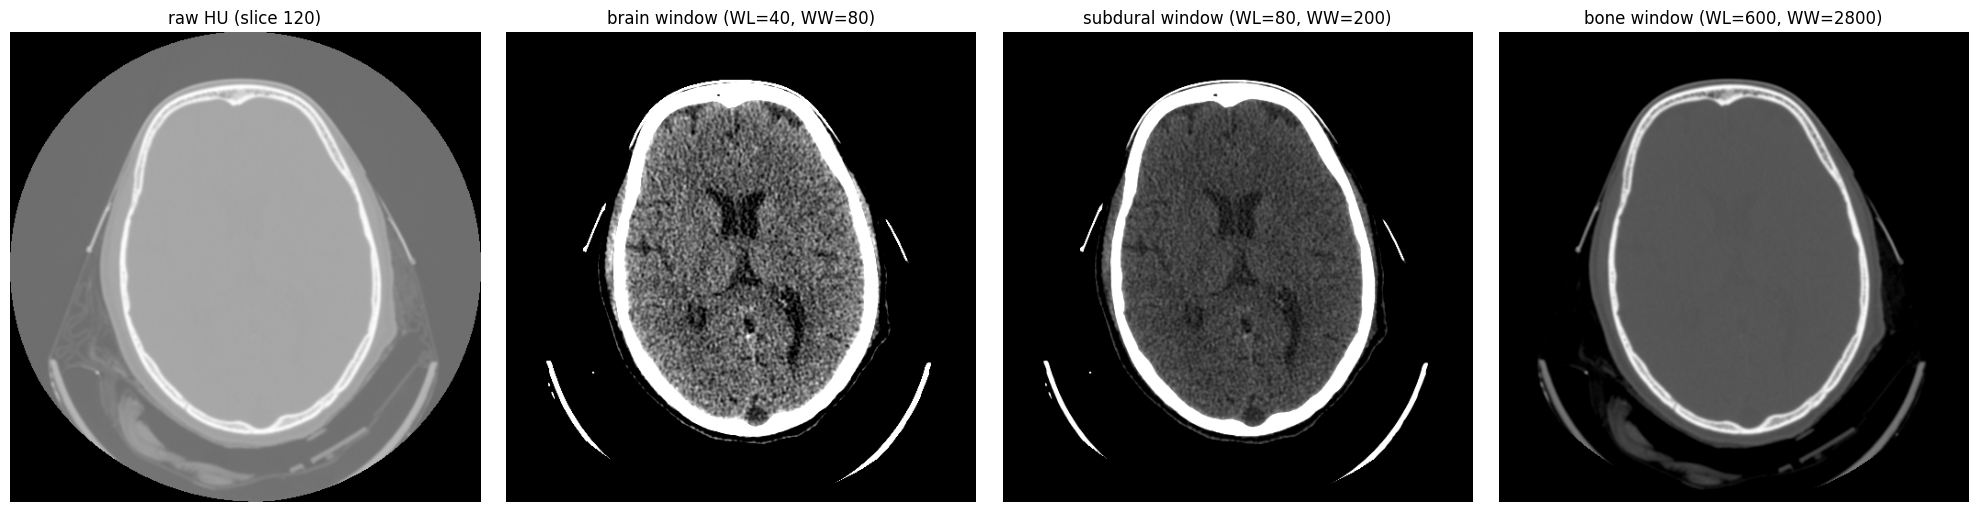

volume: (240, 512, 512), middle slice: 120
stack shape: (512, 512, 3), range: [0.00, 1.00]


In [ ]:

import matplotlib.pyplot as plt

def window(img, wl, ww):
    lo, hi = wl - ww/2, wl + ww/2
    return np.clip((img - lo) / (hi - lo), 0, 1)

def three_window(hu_slice):
    """Return 3-channel stack: brain / subdural / bone."""
    brain    = window(hu_slice, wl=40,  ww=80)
    subdural = window(hu_slice, wl=80,  ww=200)
    bone     = window(hu_slice, wl=600, ww=2800)
    return np.stack([brain, subdural, bone], axis=-1)

# Show middle slice of the loaded volume
mid_idx = vol.shape[0] // 2
mid = vol[mid_idx]
stack = three_window(mid)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(mid, cmap="gray"); axes[0].set_title(f"raw HU (slice {mid_idx})"); axes[0].axis("off")
axes[1].imshow(stack[:,:,0], cmap="gray"); axes[1].set_title("brain window (WL=40, WW=80)"); axes[1].axis("off")
axes[2].imshow(stack[:,:,1], cmap="gray"); axes[2].set_title("subdural window (WL=80, WW=200)"); axes[2].axis("off")
axes[3].imshow(stack[:,:,2], cmap="gray"); axes[3].set_title("bone window (WL=600, WW=2800)"); axes[3].axis("off")
plt.tight_layout()
plt.savefig("/content/window_check.png", dpi=100, bbox_inches="tight")
plt.show()

print(f"volume: {vol.shape}, middle slice: {mid_idx}")
print(f"stack shape: {stack.shape}, range: [{stack.min():.2f}, {stack.max():.2f}]")

In [ ]:

import torch
from torch.utils.data import Dataset
from torchvision import transforms

class CQ500ScanDataset(Dataset):
    """Yields (slices_tensor, label, folder_id) per scan.
    Samples N middle slices, applies 3-window stack, resizes to 224, ImageNet-normalizes.
    """
    def __init__(self, qct_folder, consensus_df, n_slices=30, target_label="ICH"):
        self.n_slices = n_slices
        self.items = []
        for sf in sorted(os.listdir(qct_folder)):
            result = pick_series(f"{qct_folder}/{sf}")
            if result is None:
                continue
            n, series_path, _ = result
            fid = sf.split()[0]
            lid = fid.replace("CQ500CT", "CQ500-CT-")
            row = consensus_df[consensus_df["name"] == lid]
            if len(row) != 1:
                continue
            self.items.append((fid, series_path, int(row[target_label].values[0])))
        self.tf = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
        ])

    def __len__(self): return len(self.items)

    def __getitem__(self, idx):
        fid, series_path, label = self.items[idx]
        vol = load_series_hu(series_path)
        # Sample n_slices from the middle
        z = vol.shape[0]
        start = max(0, (z - self.n_slices) // 2)
        vol = vol[start:start + self.n_slices]
        tensors = []
        for hu in vol:
            stack = (three_window(hu) * 255).astype(np.uint8)
            tensors.append(self.tf(stack))
        return torch.stack(tensors), torch.tensor(label, dtype=torch.float32), fid

# Build and inspect
import time
t0 = time.time()
ds = CQ500ScanDataset("/content/cq500_data/qct01", consensus, n_slices=30, target_label="ICH")
print(f"dataset size: {len(ds)}")

# Load first 3 to sanity-check shapes and timing
for i in range(3):
    t = time.time()
    x, y, fid = ds[i]
    print(f"  {fid}: x={tuple(x.shape)}, label={int(y)}, load_time={time.time()-t:.1f}s")

# Full label distribution across all 20
print("\ncomputing full label distribution (loads all 20 — takes ~1-2 min on CPU)...")
labels = [ds.items[i][2] for i in range(len(ds))]  # cached — no reload needed
pos = sum(labels)
print(f"ICH positives: {pos}/{len(labels)} = {100*pos/len(labels):.0f}%")
print(f"total setup time: {time.time()-t0:.1f}s")

dataset size: 20
  CQ500CT0: x=(30, 3, 224, 224), label=0, load_time=3.7s
  CQ500CT10: x=(30, 3, 224, 224), label=1, load_time=2.9s
  CQ500CT100: x=(30, 3, 224, 224), label=0, load_time=1.7s

computing full label distribution (loads all 20 — takes ~1-2 min on CPU)...
ICH positives: 9/20 = 45%
total setup time: 8.4s


In [ ]:

from torchvision import models
from sklearn.metrics import roc_auc_score

# DenseNet-121 pretrained ImageNet, random-init 1-logit head
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
model.classifier = torch.nn.Linear(model.classifier.in_features, 1)
model.eval()
torch.manual_seed(42)  # deterministic random head

t0 = time.time()
scan_probs, scan_labels, scan_ids = [], [], []
with torch.no_grad():
    for i in range(len(ds)):
        x, y, fid = ds[i]              # x: (30, 3, 224, 224)
        logits = model(x).squeeze(1)   # (30,) per-slice logits
        probs  = torch.sigmoid(logits) # (30,) per-slice probabilities
        scan_prob = probs.mean().item() # mean-pool → scan-level
        scan_probs.append(scan_prob)
        scan_labels.append(int(y))
        scan_ids.append(fid)
        print(f"  {fid}: mean_prob={scan_prob:.3f}, label={int(y)}")

auc = roc_auc_score(scan_labels, scan_probs)
print(f"\n=== END-TO-END SANITY ===")
print(f"scans processed: {len(scan_probs)}")
print(f"total time: {time.time()-t0:.0f}s (CPU inference)")
print(f"scan-level AUC (untrained head): {auc:.3f}   [expected ~0.5 for random]")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 86.2MB/s]


  CQ500CT0: mean_prob=0.551, label=0
  CQ500CT10: mean_prob=0.609, label=1
  CQ500CT100: mean_prob=0.536, label=0
  CQ500CT101: mean_prob=0.516, label=0
  CQ500CT102: mean_prob=0.490, label=1
  CQ500CT103: mean_prob=0.577, label=0
  CQ500CT104: mean_prob=0.455, label=0
  CQ500CT105: mean_prob=0.665, label=0
  CQ500CT106: mean_prob=0.609, label=1
  CQ500CT107: mean_prob=0.570, label=1
  CQ500CT108: mean_prob=0.570, label=0
  CQ500CT109: mean_prob=0.604, label=1
  CQ500CT110: mean_prob=0.646, label=0
  CQ500CT111: mean_prob=0.489, label=1
  CQ500CT112: mean_prob=0.473, label=0
  CQ500CT113: mean_prob=0.560, label=1
  CQ500CT114: mean_prob=0.468, label=1
  CQ500CT115: mean_prob=0.471, label=1
  CQ500CT116: mean_prob=0.448, label=0
  CQ500CT117: mean_prob=0.645, label=0

=== END-TO-END SANITY ===
scans processed: 20
total time: 175s (CPU inference)
scan-level AUC (untrained head): 0.475   [expected ~0.5 for random]


In [3]:
from google.colab import userdata
from huggingface_hub import login
login(token=userdata.get("HF_TOKEN"))

In [4]:
from huggingface_hub import whoami
print(whoami())

{'type': 'user', 'id': '63a85b5d32ed73936eb90bb2', 'name': 'imadix', 'fullname': 'imad lembachar', 'isPro': False, 'avatarUrl': '/avatars/8e9bd030ce91c80e641cf28503fbac5e.svg', 'orgs': [{'type': 'org', 'id': '6a98902341202d823e36f91d', 'name': 'neurosentry', 'fullname': 'neurosentry', 'avatarUrl': 'https://www.gravatar.com/avatar/5b9a43c8196336f2827c433651af3f9b?d=retro&size=100', 'roleInOrg': 'admin'}], 'auth': {'type': 'access_token', 'accessToken': {'displayName': 'neurosentry', 'role': 'fineGrained', 'createdAt': '2026-09-03T00:04:41.768Z', 'fineGrained': {'canReadGatedRepos': True, 'global': ['discussion.write'], 'scoped': [{'entity': {'_id': '6a98902341202d823e36f91d', 'type': 'org', 'name': 'neurosentry'}, 'permissions': ['repo.content.read', 'repo.access.read', 'repo.write', 'discussion.write']}, {'entity': {'_id': '63a85b5d32ed73936eb90bb2', 'type': 'user', 'name': 'imadix'}, 'permissions': ['repo.content.read', 'repo.access.read', 'repo.write', 'discussion.write']}]}}}}


In [5]:
import os
from huggingface_hub import hf_hub_download

os.makedirs("/content/cq500", exist_ok=True)

# labels (few KB, instant)
for f in ("reads.csv", "prediction_probabilities.csv"):
    hf_hub_download("neurosentry/cq500", f, repo_type="dataset", local_dir="/content/cq500")

# qct01 data (~2.7 GB, ~30 seconds via HF)
tar_path = hf_hub_download("neurosentry/cq500", "qct01.tar",
                            repo_type="dataset", local_dir="/content/cq500")
print(f"downloaded: {tar_path}")

reads.csv:   0%|          | 0.00/50.0k [00:00<?, ?B/s]

prediction_probabilities.csv:   0%|          | 0.00/28.4k [00:00<?, ?B/s]

qct01.tar: reconstructing file:   0%|          |  0.00B / 2.65GB            

qct01.tar: downloading bytes:           |  0.00B            

downloaded: /content/cq500/qct01.tar


In [6]:
import subprocess
os.makedirs("/content/cq500_data", exist_ok=True)
subprocess.run(["tar", "-xf", tar_path, "-C", "/content/cq500_data"], check=True)
os.remove(tar_path)  # free 2.7 GB
print(f"scans in qct01: {len(os.listdir('/content/cq500_data/qct01'))}")

scans in qct01: 20


In [1]:
!pip install -q -U huggingface_hub pydicom pylibjpeg pylibjpeg-libjpeg python-gdcm

import os, subprocess, re, time
import numpy as np, pandas as pd, pydicom, torch
from google.colab import userdata
from huggingface_hub import login, hf_hub_download
from torchvision import transforms

# --- HF login + pull ---
login(token=userdata.get("HF_TOKEN"))
os.makedirs("/content/cq500", exist_ok=True)
os.makedirs("/content/cq500_data", exist_ok=True)
for f in ("reads.csv", "prediction_probabilities.csv"):
    hf_hub_download("neurosentry/cq500", f, repo_type="dataset", local_dir="/content/cq500")
tar_path = hf_hub_download("neurosentry/cq500", "qct01.tar", repo_type="dataset",
                            local_dir="/content/cq500")
subprocess.run(["tar", "-xf", tar_path, "-C", "/content/cq500_data"], check=True)
os.remove(tar_path)

# --- utilities ---
BAD = re.compile(r"(post\s*contrast|d3d|bone|arterial|venous|perfusion|cta)", re.I)
GOOD = re.compile(r"(plain|stnd|pre\s*contrast)", re.I)

def pick_series(sf):
    pref, fb = [], []
    for study in os.listdir(sf):
        sp = f"{sf}/{study}"
        for s in os.listdir(sp):
            if BAD.search(s): continue
            path = f"{sp}/{s}"
            n = sum(1 for f in os.listdir(path) if f.endswith(".dcm"))
            (pref if GOOD.search(s) else fb).append((n, path, s))
    pool = pref or fb
    if not pool: return None
    pool.sort(reverse=True); return pool[0]

def load_series_hu(sp):
    slices = []
    for fn in os.listdir(sp):
        if not fn.endswith(".dcm"): continue
        try:
            d = pydicom.dcmread(f"{sp}/{fn}")
            z = float(d.ImagePositionPatient[2]) if hasattr(d, "ImagePositionPatient") \
                else int(getattr(d, "InstanceNumber", 0))
            slices.append((z, d))
        except: continue
    slices.sort(key=lambda x: x[0])
    vol = []
    for _, d in slices:
        img = d.pixel_array.astype(np.float32)
        img = img * float(getattr(d, "RescaleSlope", 1) or 1) + float(getattr(d, "RescaleIntercept", 0) or 0)
        if getattr(d, "PhotometricInterpretation", "") == "MONOCHROME1":
            img = img.max() - img
        vol.append(img)
    return np.stack(vol, axis=0)

def window(img, wl, ww):
    lo, hi = wl - ww/2, wl + ww/2
    return np.clip((img - lo) / (hi - lo), 0, 1)

def three_window(hu):
    return np.stack([window(hu, 40, 80), window(hu, 80, 200), window(hu, 600, 2800)], axis=-1)

tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225]),
])

print(f"scans in qct01: {len(os.listdir('/content/cq500_data/qct01'))}   utilities defined")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 796.8/796.8 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 111.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 98.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 118.5 MB/s eta 0:00:00


reads.csv:   0%|          | 0.00/50.0k [00:00<?, ?B/s]

prediction_probabilities.csv:   0%|          | 0.00/28.4k [00:00<?, ?B/s]

qct01.tar: reconstructing file:   0%|          |  0.00B / 2.65GB            

qct01.tar: downloading bytes:           |  0.00B            

scans in qct01: 20   utilities defined


In [2]:
# labels — 2-of-3 radiologist majority vote
reads = pd.read_csv("/content/cq500/reads.csv")
consensus = pd.DataFrame({"name": reads["name"]})
consensus["ICH"] = (reads[["R1:ICH", "R2:ICH", "R3:ICH"]].sum(axis=1) >= 2).astype(int)

# preload 20 scans: for each, pick series → load HU volume → take 30 middle slices
# → 3-window stack → resize → normalize → stack into tensor (30, 3, 224, 224)
N_SLICES = 30
data = []
t0 = time.time()
for sf in sorted(os.listdir("/content/cq500_data/qct01")):
    r = pick_series(f"/content/cq500_data/qct01/{sf}")
    if r is None: continue
    _, series_path, _ = r
    fid = sf.split()[0]
    row = consensus[consensus["name"] == fid.replace("CQ500CT", "CQ500-CT-")]
    if len(row) != 1: continue
    vol = load_series_hu(series_path)
    z = vol.shape[0]
    start = max(0, (z - N_SLICES) // 2)
    vol = vol[start:start + N_SLICES]
    tensors = torch.stack([tf((three_window(s) * 255).astype(np.uint8)) for s in vol])
    data.append((fid, tensors, int(row["ICH"].values[0])))

pos = sum(d[2] for d in data)
print(f"preloaded {len(data)} scans in {time.time()-t0:.0f}s   labels: {pos} pos / {len(data)}")

preloaded 20 scans in 67s   labels: 9 pos / 20


In [3]:
import random
from torch import nn
from torchvision import models
from sklearn.metrics import roc_auc_score
from torch.amp import GradScaler, autocast

DEVICE = "cuda"
SEED = 42
random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# stratified split: 2 pos + 2 neg for val, rest for train
pos = [i for i, d in enumerate(data) if d[2] == 1]
neg = [i for i, d in enumerate(data) if d[2] == 0]
random.shuffle(pos); random.shuffle(neg)
val_idx = pos[:2] + neg[:2]
train_idx = pos[2:] + neg[2:]
print(f"train: {len(train_idx)} (pos={sum(data[i][2] for i in train_idx)})   "
      f"val: {len(val_idx)} (pos={sum(data[i][2] for i in val_idx)})")

# DenseNet-121 pretrained on ImageNet, replace 1000-class head with 1-output for ICH yes/no
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
model.classifier = nn.Linear(model.classifier.in_features, 1)
model = model.to(DEVICE)

opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
loss_fn = nn.BCEWithLogitsLoss()
scaler = GradScaler("cuda")

def evaluate():
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for i in val_idx:
            _, x, y = data[i]
            x = x.to(DEVICE, non_blocking=True)
            with autocast("cuda"):
                logits = model(x).squeeze(1)
            ps.append(torch.sigmoid(logits).float().mean().item()); ys.append(y)
    return roc_auc_score(ys, ps)

EPOCHS = 3
best_auc = 0.0
for ep in range(1, EPOCHS + 1):
    model.train()
    random.shuffle(train_idx)
    running, count = 0.0, 0
    for i in train_idx:
        _, x, y = data[i]                                # x: (30, 3, 224, 224)
        x = x.to(DEVICE, non_blocking=True)
        y_batch = torch.full((x.size(0),), float(y), device=DEVICE)  # replicate scan label to each slice
        opt.zero_grad()
        with autocast("cuda"):
            loss = loss_fn(model(x).squeeze(1), y_batch)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        running += loss.item() * x.size(0); count += x.size(0)
    val_auc = evaluate()
    print(f"epoch {ep}  train_loss={running/count:.4f}  val_auc={val_auc:.4f}")
    if val_auc > best_auc:
        best_auc = val_auc
        torch.save(model.state_dict(), "/content/best.pt")

print(f"\n=== DONE ===  best val AUC: {best_auc:.4f}")
print(f"checkpoint saved at: /content/best.pt")

train: 16 (pos=7)   val: 4 (pos=2)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 74.4MB/s]


epoch 1  train_loss=0.7064  val_auc=0.5000
epoch 2  train_loss=0.6394  val_auc=1.0000
epoch 3  train_loss=0.5656  val_auc=0.7500

=== DONE ===  best val AUC: 1.0000
checkpoint saved at: /content/best.pt


In [1]:
from huggingface_hub import HfApi, create_repo

REPO = "neurosentry/ich-classifier"
create_repo(REPO, repo_type="model", exist_ok=True, private=False)

HfApi().upload_file(
    path_or_fileobj="/content/best.pt",
    path_in_repo="week1_imad_densenet_qct01.pt",
    repo_id=REPO, repo_type="model",
)
print(f"model pushed to: https://huggingface.co/{REPO}/blob/main/week1_imad_densenet_qct01.pt")

ValueError: Provided path: '/content/best.pt' is not a file on the local file system

In [4]:
!pip install -q -U huggingface_hub pydicom pylibjpeg pylibjpeg-libjpeg python-gdcm

import os, subprocess, re, time, random
import numpy as np, pandas as pd, pydicom, torch
from google.colab import userdata
from huggingface_hub import login, hf_hub_download
from torchvision import transforms, models
from torch import nn
from sklearn.metrics import roc_auc_score
from torch.amp import GradScaler, autocast

# --- HF login + data pull ---
login(token=userdata.get("HF_TOKEN"))
os.makedirs("/content/cq500", exist_ok=True)
os.makedirs("/content/cq500_data", exist_ok=True)
hf_hub_download("neurosentry/cq500", "reads.csv", repo_type="dataset", local_dir="/content/cq500")
tar_path = hf_hub_download("neurosentry/cq500", "qct01.tar", repo_type="dataset", local_dir="/content/cq500")
subprocess.run(["tar", "-xf", tar_path, "-C", "/content/cq500_data"], check=True)
os.remove(tar_path)

# --- utilities ---
BAD = re.compile(r"(post\s*contrast|d3d|bone|arterial|venous|perfusion|cta)", re.I)
GOOD = re.compile(r"(plain|stnd|pre\s*contrast)", re.I)
def pick_series(sf):
    pref, fb = [], []
    for study in os.listdir(sf):
        sp = f"{sf}/{study}"
        for s in os.listdir(sp):
            if BAD.search(s): continue
            path = f"{sp}/{s}"
            n = sum(1 for f in os.listdir(path) if f.endswith(".dcm"))
            (pref if GOOD.search(s) else fb).append((n, path, s))
    pool = pref or fb
    if not pool: return None
    pool.sort(reverse=True); return pool[0]

def load_series_hu(sp):
    slices = []
    for fn in os.listdir(sp):
        if not fn.endswith(".dcm"): continue
        try:
            d = pydicom.dcmread(f"{sp}/{fn}")
            z = float(d.ImagePositionPatient[2]) if hasattr(d, "ImagePositionPatient") else int(getattr(d, "InstanceNumber", 0))
            slices.append((z, d))
        except: continue
    slices.sort(key=lambda x: x[0])
    vol = []
    for _, d in slices:
        img = d.pixel_array.astype(np.float32)
        img = img * float(getattr(d, "RescaleSlope", 1) or 1) + float(getattr(d, "RescaleIntercept", 0) or 0)
        if getattr(d, "PhotometricInterpretation", "") == "MONOCHROME1":
            img = img.max() - img
        vol.append(img)
    return np.stack(vol, axis=0)

def window(img, wl, ww):
    lo, hi = wl - ww/2, wl + ww/2
    return np.clip((img - lo) / (hi - lo), 0, 1)

def three_window(hu):
    return np.stack([window(hu, 40, 80), window(hu, 80, 200), window(hu, 600, 2800)], axis=-1)

tf = transforms.Compose([
    transforms.ToPILImage(), transforms.Resize((224, 224)),
    transforms.ToTensor(), transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225]),
])

# --- labels + preload ---
reads = pd.read_csv("/content/cq500/reads.csv")
consensus = pd.DataFrame({"name": reads["name"]})
consensus["ICH"] = (reads[["R1:ICH", "R2:ICH", "R3:ICH"]].sum(axis=1) >= 2).astype(int)

N_SLICES = 30
data = []
t0 = time.time()
for sf in sorted(os.listdir("/content/cq500_data/qct01")):
    r = pick_series(f"/content/cq500_data/qct01/{sf}")
    if r is None: continue
    _, series_path, _ = r
    fid = sf.split()[0]
    row = consensus[consensus["name"] == fid.replace("CQ500CT", "CQ500-CT-")]
    if len(row) != 1: continue
    vol = load_series_hu(series_path)
    z = vol.shape[0]
    start = max(0, (z - N_SLICES) // 2)
    vol = vol[start:start + N_SLICES]
    tensors = torch.stack([tf((three_window(s) * 255).astype(np.uint8)) for s in vol])
    data.append((fid, tensors, int(row["ICH"].values[0])))
print(f"preloaded {len(data)} scans in {time.time()-t0:.0f}s   labels: {sum(d[2] for d in data)} pos")

# --- train ---
DEVICE = "cuda"; SEED = 42
random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
pos = [i for i, d in enumerate(data) if d[2] == 1]
neg = [i for i, d in enumerate(data) if d[2] == 0]
random.shuffle(pos); random.shuffle(neg)
val_idx = pos[:2] + neg[:2]
train_idx = pos[2:] + neg[2:]

model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
model.classifier = nn.Linear(model.classifier.in_features, 1)
model = model.to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
loss_fn = nn.BCEWithLogitsLoss()
scaler = GradScaler("cuda")

def evaluate():
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for i in val_idx:
            _, x, y = data[i]
            x = x.to(DEVICE, non_blocking=True)
            with autocast("cuda"): logits = model(x).squeeze(1)
            ps.append(torch.sigmoid(logits).float().mean().item()); ys.append(y)
    return roc_auc_score(ys, ps)

best_auc = 0.0
for ep in range(1, 4):
    model.train(); random.shuffle(train_idx); running, count = 0.0, 0
    for i in train_idx:
        _, x, y = data[i]
        x = x.to(DEVICE, non_blocking=True)
        y_batch = torch.full((x.size(0),), float(y), device=DEVICE)
        opt.zero_grad()
        with autocast("cuda"):
            loss = loss_fn(model(x).squeeze(1), y_batch)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        running += loss.item() * x.size(0); count += x.size(0)
    val_auc = evaluate()
    print(f"epoch {ep}  train_loss={running/count:.4f}  val_auc={val_auc:.4f}")
    if val_auc > best_auc:
        best_auc = val_auc
        torch.save(model.state_dict(), "/content/best.pt")

print(f"\n=== DONE ===  best val AUC: {best_auc:.4f}   saved: /content/best.pt")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 796.8/796.8 kB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 108.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 110.3 MB/s eta 0:00:00


reads.csv:   0%|          | 0.00/50.0k [00:00<?, ?B/s]

qct01.tar: reconstructing file:   0%|          |  0.00B / 2.65GB            

qct01.tar: downloading bytes:           |  0.00B            

preloaded 20 scans in 58s   labels: 9 pos
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 189MB/s]


epoch 1  train_loss=0.7064  val_auc=0.5000
epoch 2  train_loss=0.6394  val_auc=1.0000
epoch 3  train_loss=0.5656  val_auc=0.7500

=== DONE ===  best val AUC: 1.0000   saved: /content/best.pt


In [5]:
from huggingface_hub import HfApi, create_repo

REPO = "neurosentry/ich-classifier"
create_repo(REPO, repo_type="model", exist_ok=True, private=False)

HfApi().upload_file(
    path_or_fileobj="/content/best.pt",
    path_in_repo="week1_imad_densenet_qct01.pt",
    repo_id=REPO, repo_type="model",
)
print(f"pushed to: https://huggingface.co/{REPO}/blob/main/week1_imad_densenet_qct01.pt")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /content/best.pt            :   0%|          | 75.8kB / 28.4MB            

pushed to: https://huggingface.co/neurosentry/ich-classifier/blob/main/week1_imad_densenet_qct01.pt
